## Lab 4: Diffusion Models for Anomaly Detection (Tabular Data)

**Alejandro Lancho Serrano, Vanessa Gómez Verdejo, Pablo Martínez Olmos, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='http://www.tsc.uc3m.es/~emipar/BBVA/INTRO/img/logo_uc3m_foot.jpg' width=400 />

In this lab, you will build an **unsupervised anomaly detection system** for credit card fraud using **diffusion models**, and compare it against classical and neural baselines.

You are given:
- basic library imports,
- the dataset.

From this point on, **you are responsible for designing, implementing, and evaluating the models**.

---

## Objectives

By the end of this lab, you should be able to:

- Apply **diffusion models** to tabular data.
- Use **denoising difficulty** as an anomaly score.
- Evaluate anomaly detectors under **extreme class imbalance**.
- Select and justify **decision thresholds**.
- Compare modern generative models with **strong baselines**.

---

## Tasks

### 1. Exploratory Data Analysis (EDA)
- Load the dataset and inspect the class imbalance.
- Visualize at least one informative feature (e.g., `Amount`) by class.
- Explain why **AUPRC** is more informative than accuracy in this setting.

*Expected outputs:* brief plots + 2–3 sentences of interpretation.

---

### 2. Diffusion Model for Tabular Data
- Implement a **forward diffusion process** for tabular vectors:
  - Choose a noise schedule (linear or cosine).
  - Implement the noising operation $ x_t $.
- Build a **denoising neural network** (MLP):
  - Input: noised data + time embedding.
  - Output: predicted noise.
- Train the model **only on normal transactions**.

*Expected outputs:* training loss curve + explanation of design choices.

---

### 3. Diffusion-Based Anomaly Scoring
Implement **at least one** of the following anomaly scores:
- **Residual-based score:** noise prediction error.
- **Reconstruction-based score:** error in reconstructed $ \hat{x}_0 $.

- Aggregate scores over multiple random timesteps.
- Explain why stochastic averaging is useful.

*Expected outputs:* function to compute scores + short explanation.

---

### 4. Evaluation (No Threshold Yet)
- Evaluate diffusion scores on **validation and test sets** using:
  - AUROC
  - AUPRC
- Plot Precision–Recall curves.
- Compare results to the random baseline.

*Expected outputs:* metrics + PR curves + interpretation.

---

### 5. Threshold Selection
Using the **validation set only**:
- Implement at least two thresholding strategies:
  - target precision or recall,
  - max-F1.
- Visualize confusion matrices for different thresholds.
- Discuss the trade-off between false positives and false negatives.

*Expected outputs:* confusion matrices + discussion.

---

### 6. Final Test Evaluation
- Fix **one threshold** chosen on validation.
- Apply it **once** to the test set.
- Report:
  - confusion matrix,
  - precision, recall, FPR, F1.

*Expected outputs:* final test results + interpretation.

---

### 7. Baseline Comparisons
Implement and evaluate **at least two baselines** (e.g.):
- **Isolation Forest**
- **Autoencoder**

Requirements:
- Train on normal samples only.
- Use the same evaluation metrics and splits.
- Produce comparable anomaly scores.

*Expected outputs:* AUROC/AUPRC on test set + PR curves.

---

### 8. Comparative Analysis
- Summarize results for:
  - Diffusion model
  - Isolation Forest
  - Autoencoder

  

*Expected outputs* must include answers to:
  - Which method performs best here?
  - Why might that be the case?
  - What does diffusion offer beyond raw performance?


## Setting Things Up <a id="setup"></a>

In [1]:
# ======================================================
# Setup: imports, device, and reproducibility
# ======================================================

# --- Standard library ---
import os
import math
import random
import time
import json
import subprocess
import sys
from pathlib import Path
from typing import Tuple

# --- Numerical & data handling ---
import numpy as np
import pandas as pd

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- PyTorch ---
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# --- Scikit-learn ---
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    f1_score,
    confusion_matrix,
)
from sklearn.ensemble import IsolationForest

# --- Device setup ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# --- Reproducibility ---
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

Using device: cpu


## Dataset <a id="data"></a>

We use the **Credit Card Fraud Detection** dataset introduced by Dal Pozzolo et al. (2015),  
containing **284,807 transactions** with a severe class imbalance  
(**fraud ≈ 0.17%**).

The dataset consists of:
- anonymized PCA features (`V1`–`V28`),
- transaction `Amount`,
- binary label `Class` (0 = normal, 1 = fraud).

---

### Automatic download options

To make the lab reproducible across environments, the notebook attempts to obtain  
`creditcard.csv` using the following **fallback chain**:

1. **Local file (fastest)**  
   - If `./data/creditcard.csv` already exists, it is loaded directly.

2. **Kaggle API (optional)**  
   - Requires a Kaggle API token at `~/.kaggle/kaggle.json`.  
   - You can generate this from *Kaggle → Account → Create API Token*.

3. **OpenML mirror (no credentials)**  
   - Downloads the same dataset via OpenML (dataset ID 1597).  
   - May be blocked on some institutional networks.

4. **Direct HTTP mirror**  
   - Downloads the dataset from a public mirror.  
   - Requires no credentials and works in most environments.

The dataset is always saved locally to: `./data/creditcard.csv`

---

### Manual fallback

If all automatic methods fail (e.g., no internet access),  
download `creditcard.csv` manually and place it in `./data/`, then re-run the notebook.

---

> **Note:**  
> All experiments in this lab use the same dataset splits and evaluation protocol,  
> regardless of which download method is used.

In [2]:
# ======================================================
# Downloader + Loader for creditcard.csv
# Priority:
#   1) Local file
#   2) Kaggle (if credentials exist)
#   3) OpenML
#   4) Direct HTTP fallback (recommended for teaching)
# ======================================================

DATA_DIR = Path("./data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "creditcard.csv"


# ------------------------------------------------------
# Utility helpers
# ------------------------------------------------------

def have_kaggle_creds():
    kaggle_json = Path.home() / ".kaggle" / "kaggle.json"
    return kaggle_json.exists()


def ensure_pkg(pkg):
    try:
        __import__(pkg)
        return True
    except ImportError:
        print(f"Installing {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return True


# ------------------------------------------------------
# Kaggle download
# ------------------------------------------------------

def download_via_kaggle():
    """
    Requires:
      - ~/.kaggle/kaggle.json present (Kaggle API credentials)
      - Internet access
    """
    print("Attempting Kaggle download...")
    ensure_pkg("kaggle")

    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    os.chmod(kaggle_dir, 0o700)

    kj = kaggle_dir / "kaggle.json"
    if not kj.exists():
        print("No kaggle.json found at ~/.kaggle/kaggle.json")
        return False
    os.chmod(kj, 0o600)

    try:
        subprocess.check_call([
            sys.executable, "-m", "kaggle", "datasets", "download",
            "-d", "mlg-ulb/creditcardfraud",
            "-p", str(DATA_DIR),
            "-f", "creditcard.csv"
        ])

        if CSV_PATH.exists():
            print(f"Found {CSV_PATH}")
            return True

        # Fallback: extract from zip if needed
        import zipfile
        for z in DATA_DIR.glob("*.zip"):
            with zipfile.ZipFile(z, "r") as zf:
                if "creditcard.csv" in zf.namelist():
                    zf.extract("creditcard.csv", DATA_DIR)
                    print(f"Extracted creditcard.csv from {z}")
                    return True

        print("Kaggle download did not produce creditcard.csv")
        return False

    except subprocess.CalledProcessError as e:
        print("Kaggle download failed:", e)
        return False


# ------------------------------------------------------
# OpenML download
# ------------------------------------------------------

def download_via_openml():
    """
    Uses openml-python to fetch the dataset.
    Often blocked on institutional networks.
    """
    print("Attempting OpenML download...")
    ensure_pkg("openml")
    import openml

    try:
        # OpenML ID commonly associated with creditcard fraud
        ds = openml.datasets.get_dataset(1597)

        X, y, categorical, attribute_names = ds.get_data(
            dataset_format="dataframe",
            target=ds.default_target_attribute
        )

        df = X.copy()
        df["Class"] = y
        df.to_csv(CSV_PATH, index=False)

        print(f"Saved {CSV_PATH} via OpenML")
        return True

    except Exception as e:
        print("OpenML download failed:", e)
        return False


# ------------------------------------------------------
# Direct HTTP fallback (RECOMMENDED)
# ------------------------------------------------------

def download_via_http():
    """
    Direct public mirror.
    No credentials, works in most environments.
    """
    print("Attempting direct HTTP download...")
    url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

    try:
        df = pd.read_csv(url)
        df.to_csv(CSV_PATH, index=False)
        print(f"Saved {CSV_PATH} via HTTP")
        return True
    except Exception as e:
        print("HTTP download failed:", e)
        return False


# ------------------------------------------------------
# Unified loader
# ------------------------------------------------------

def load_creditcard_csv():
    if CSV_PATH.exists():
        print(f"Loading local {CSV_PATH}")
        return pd.read_csv(CSV_PATH)

    if have_kaggle_creds() and download_via_kaggle():
        return pd.read_csv(CSV_PATH)

    if download_via_openml():
        return pd.read_csv(CSV_PATH)

    if download_via_http():
        return pd.read_csv(CSV_PATH)

    raise FileNotFoundError(
        "Could not obtain creditcard.csv.\n"
        "Please place the file manually at ./data/creditcard.csv and re-run."
    )


# ------------------------------------------------------
# Execute
# ------------------------------------------------------

df = load_creditcard_csv()
print("Dataset shape:", df.shape)
print("First columns:", df.columns.tolist()[:10], "...")
print("Class distribution:", df["Class"].value_counts().to_dict())

Attempting OpenML download...
Installing openml ...
Saved data/creditcard.csv via OpenML
Dataset shape: (284807, 30)
First columns: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10'] ...
Class distribution: {0: 284315, 1: 492}


**Objetivo 1**: Exploratory Data Analysis (EDA) y Preprocesamiento
Además de los gráficos que pide el enunciado, en este bloque separamos los datos en Entrenamiento, Validación y Test, asegurándonos de que el conjunto de entrenamiento tenga SOLO transacciones normales (Class == 0), ya que el modelo debe aprender únicamente qué es lo "normal".

Transacciones Normales (0): 284315
Transacciones Fraudulentas (1): 492 (0.1727%)


/tmp/ipykernel_2041/508012651.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, ax=axes[0], palette=['#3498db', '#e74c3c'])
/tmp/ipykernel_2041/508012651.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Normal (0)', 'Fraude (1)'])


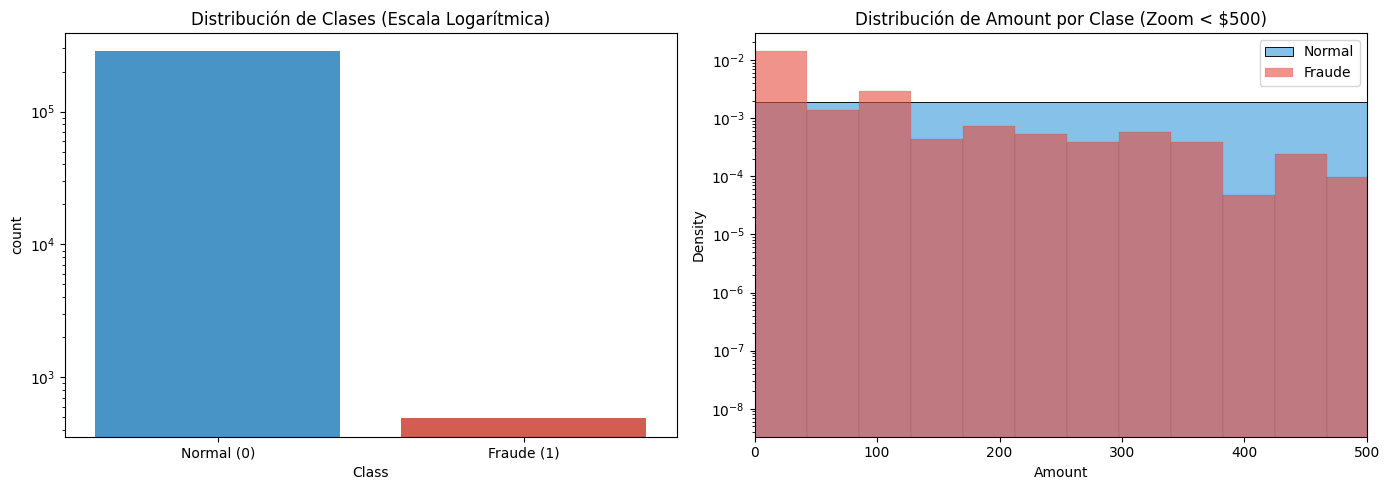

Shape Entrenamiento (Solo Normales): (199020, 29)
Shape Validación: (42893, 29) (Fraudes: 246)
Shape Test: (42894, 29) (Fraudes: 246)


In [3]:
# ======================================================
#
# Task 1: Exploratory Data Analysis (EDA) & Data Splitting
#
# ======================================================

# 1. Inspeccionar el desbalance de clases
class_counts = df['Class'].value_counts()
fraud_ratio = class_counts[1] / len(df) * 100
print(f"Transacciones Normales (0): {class_counts[0]}")
print(f"Transacciones Fraudulentas (1): {class_counts[1]} ({fraud_ratio:.4f}%)")

# 2. Visualizar el desbalance y la variable 'Amount' por clase
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de barras de clases (escala logarítmica para poder ver la barra de fraude)
sns.countplot(x='Class', data=df, ax=axes[0], palette=['#3498db', '#e74c3c'])
axes[0].set_yscale('log')
axes[0].set_title('Distribución de Clases (Escala Logarítmica)')
axes[0].set_xticklabels(['Normal (0)', 'Fraude (1)'])

# Distribución de 'Amount' (Monto de la transacción) por clase
sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, color='#3498db', label='Normal', stat='density', ax=axes[1], alpha=0.6)
sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, color='#e74c3c', label='Fraude', stat='density', ax=axes[1], alpha=0.6)
axes[1].set_xlim(0, 500) # Hacemos zoom entre 0 y 500 para ver mejor las diferencias
axes[1].set_yscale('log')
axes[1].set_title('Distribución de Amount por Clase (Zoom < $500)')
axes[1].legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------
# Preprocesamiento y División de Datos (Crucial para todo el Lab)
# ------------------------------------------------------
# Eliminamos 'Time' si existe porque suele meter ruido temporal no estacionario, nos quedamos con V1-V28 y Amount
features = [c for c in df.columns if c not in ['Class', 'Time']]
X = df[features].values
y = df['Class'].values.astype(int)

# Separamos las transacciones normales de las fraudulentas
X_normal = X[y == 0]
X_fraud = X[y == 1]

# Usamos el 70% de las normales SOLO para entrenar (sin ningún fraude)
X_train_norm, X_temp_norm = train_test_split(X_normal, test_size=0.30, random_state=42)

# El 30% restante de normales lo dividimos mitad y mitad para Validación y Test
X_val_norm, X_test_norm = train_test_split(X_temp_norm, test_size=0.50, random_state=42)

# Los fraudes los dividimos mitad y mitad entre Validación y Test
X_val_fraud, X_test_fraud = train_test_split(X_fraud, test_size=0.50, random_state=42)

# Armamos los conjuntos finales de Validación y Test juntando normales + fraudes
X_val = np.vstack([X_val_norm, X_val_fraud])
y_val = np.hstack([np.zeros(len(X_val_norm)), np.ones(len(X_val_fraud))])

X_test = np.vstack([X_test_norm, X_test_fraud])
y_test = np.hstack([np.zeros(len(X_test_norm)), np.ones(len(X_test_fraud))])

# Escalamos los datos (MUY IMPORTANTE: ajustamos el StandardScaler SOLO con datos de entrenamiento)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_norm)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Shape Entrenamiento (Solo Normales): {X_train_scaled.shape}")
print(f"Shape Validación: {X_val_scaled.shape} (Fraudes: {int(y_val.sum())})")
print(f"Shape Test: {X_test_scaled.shape} (Fraudes: {int(y_test.sum())})")

¿Por qué AUPRC es más informativo que Accuracy? Como los fraudes son apenas el 0.17% de los datos, un modelo "tonto" que diga siempre "todo es normal" tendría un 99.83% de Accuracy sin detectar ni un solo robo. En cambio, AUPRC (Área bajo la curva Precisión-Recall) se enfoca directamente en la clase minoritaria (fraudes), evaluando cuántos fraudes reales atrapamos (Recall) sin llenar de falsas alarmas a los clientes (Precision)


**Objetivo 2**: Modelo de Difusión para Datos Tabulares



Entrenando el modelo de difusión (solo con datos normales)...
Epoch [1/20] - Loss (MSE del Ruido): 0.6676
Epoch [5/20] - Loss (MSE del Ruido): 0.4429
Epoch [10/20] - Loss (MSE del Ruido): 0.4069
Epoch [15/20] - Loss (MSE del Ruido): 0.3810
Epoch [20/20] - Loss (MSE del Ruido): 0.3713


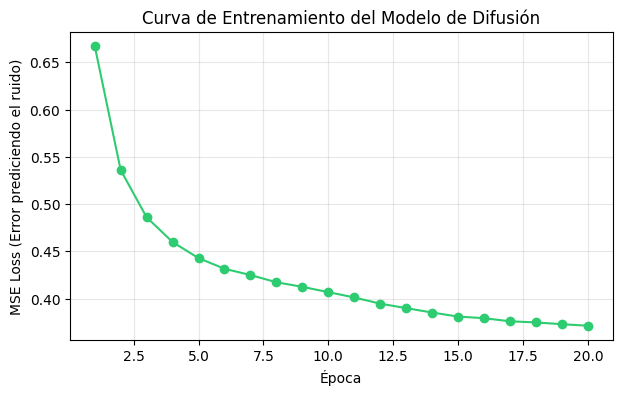

In [4]:
# ======================================================
# Task 2: Diffusion Model for Tabular Data
# ======================================================

# ------------------------------------------------------
# PARTE 1: El "Calendario de Suciedad" (Forward Diffusion Schedule)
# ------------------------------------------------------
# Imagina que tienes una foto limpia de un perrito (nuestro dato original x_0).
# Tenemos una máquina que le tira arena (ruido) en T=100 pasos.
# En el paso 1 le tira poquita arena. En el paso 100, hay tanta arena que ya no se ve el perrito.

class DiffusionSchedule:
    def __init__(self, timesteps=100, beta_start=1e-4, beta_end=0.02, device="cpu"):
        self.timesteps = timesteps # Cantidad total de pasos de ensuciado (T)
        self.device = device

        # 'betas' es cuánta arena nueva tiramos en cada paso t.
        # Empieza muy poquito (0.0001) y sube linealmente hasta 0.02.
        self.betas = torch.linspace(beta_start, beta_end, timesteps, device=device)

        # 'alphas' es cuánto del dibujo original se conserva en ese paso individual (1 - beta).
        self.alphas = 1.0 - self.betas

        # 'alpha_hat' (o alpha_bar) es el producto acumulado:
        # nos dice cuánto del dibujo original queda vivo desde el paso 0 hasta el paso 't' directamente.
        # Gracias a esta magia matemática, si queremos ver cómo queda la foto en el paso 50,
        # ¡no hace falta ensuciarla 50 veces una por una! Saltamos directo al paso 50 con una fórmula.
        self.alpha_hat = torch.cumprod(self.alphas, dim=0)

    def add_noise(self, x_0, t):
        """
        Esta función toma el dato limpio (x_0) y el número de paso (t),
        y nos devuelve el dato sucio (x_t) junto con la arena exacta (noise) que le tiró.
        """
        # 1. Creamos arena al azar (ruido Gaussiano con media 0 y varianza 1) del mismo tamaño que x_0
        noise = torch.randn_like(x_0)

        # 2. Buscamos en nuestro calendario cuánto dibujo original queda en el paso 't' (sqrt_alpha_hat)
        # y cuánta arena toca poner en el paso 't' (sqrt_one_minus_alpha_hat)
        sqrt_alpha_hat = torch.sqrt(self.alpha_hat[t]).unsqueeze(1)
        sqrt_one_minus_alpha_hat = torch.sqrt(1.0 - self.alpha_hat[t]).unsqueeze(1)

        # 3. Mezclamos el dato limpio con la arena según la receta del paso 't':
        # Fórmula oficial: x_t = sqrt(alpha_hat_t) * x_0 + sqrt(1 - alpha_hat_t) * noise
        x_t = sqrt_alpha_hat * x_0 + sqrt_one_minus_alpha_hat * noise

        return x_t, noise


# ------------------------------------------------------
# PARTE 2: El "Reloj" y el "Detective Limpiador" (Red Neuronal MLP)
# ------------------------------------------------------
# El Detective (la red neuronal) recibe el dato sucio (x_t) y tiene que adivinar:
# "¿Qué arena le tiraron a este dato?".
# Pero para adivinar bien, necesita saber en qué paso de suciedad estamos (no es lo mismo
# limpiar algo del paso 2 que algo del paso 99). Para eso sirve el Time Embedding (el reloj).

class SinusoidalTimeEmbedding(nn.Module):
    """
    Convierte un número entero (ej: paso t=45) en un vector de números (ondas seno y coseno)
    para que la red neuronal entienda fácilmente en qué momento del tiempo está.
    """
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=t.device) * -emb)
        emb = t[:, None].float() * emb[None, :]
        emb = torch.cat((emb.sin(), emb.cos()), dim=-1)
        return emb


class DenoisingMLP(nn.Module):
    """
    Nuestro Detective: Una red neuronal para datos tabulares (MLP).
    - Entrada: Los datos sucios (x_t) + la hora del reloj (t).
    - Salida: La arena (ruido) que el detective cree que sobra en esos datos.
    """
    def __init__(self, input_dim, hidden_dim=128, time_dim=32):
        super().__init__()
        # El reloj que transforma 't' en un vector de tamaño time_dim
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU() # Función de activación suave (como ReLU pero mejor para difusión)
        )

        # El cerebro del detective: recibe (datos sucios + vector de tiempo) pegados juntos
        self.net = nn.Sequential(
            nn.Linear(input_dim + time_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, input_dim) # Devuelve un vector del mismo tamaño que el dato original
        )

    def forward(self, x_t, t):
        # 1. Miramos el reloj
        t_emb = self.time_mlp(t)
        # 2. Pegamos el dato sucio con la información del reloj
        x_input = torch.cat([x_t, t_emb], dim=1)
        # 3. Predecimos la arena (ruido)
        predicted_noise = self.net(x_input)
        return predicted_noise


# ------------------------------------------------------
# PARTE 3: Entrenamiento (SOLO con transacciones normales)
# ------------------------------------------------------
# ¿Cuál es el truco para detectar fraudes?
# Le enseñamos al Detective a limpiar SOLAMENTE transacciones normales (legítimas).
# Se vuelve un experto limpiando compras normales.
# Cuando mañana le demos un FRAUDE lleno de arena, ¡no va a saber cómo limpiarlo y se va a equivocar muchísimo!

input_dim = X_train_scaled.shape[1]
TIMESTEPS = 100
BATCH_SIZE = 512
EPOCHS = 20
LR = 1e-3

diff_schedule = DiffusionSchedule(timesteps=TIMESTEPS, device=device)
model = DenoisingMLP(input_dim=input_dim, hidden_dim=128, time_dim=32).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# Preparamos los datos normales en una cinta transportadora (DataLoader)
train_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

loss_history = []

print("Entrenando el modelo de difusión (solo con datos normales)...")
model.train()
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    for (x_0_batch,) in train_loader:
        x_0_batch = x_0_batch.to(device)

        # 1. Elegimos un paso de tiempo 't' al azar para cada transacción del lote (entre 0 y 99)
        t = torch.randint(0, TIMESTEPS, (x_0_batch.size(0),), device=device).long()

        # 2. Ensuciamos las transacciones limpias hasta ese paso 't'
        x_t, true_noise = diff_schedule.add_noise(x_0_batch, t)

        # 3. Le pedimos al Detective que adivine qué arena (ruido) le pusimos
        predicted_noise = model(x_t, t)

        # 4. Calculamos el error: comparamos la arena real (true_noise) con la que adivinó (predicted_noise)
        loss = F.mse_loss(predicted_noise, true_noise)

        # 5. El Detective aprende de su error (Backpropagation)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * x_0_batch.size(0)

    epoch_loss /= len(train_dataset)
    loss_history.append(epoch_loss)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss (MSE del Ruido): {epoch_loss:.4f}")

# Graficamos la curva de aprendizaje
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), loss_history, marker='o', color='#2ecc71')
plt.title('Curva de Entrenamiento del Modelo de Difusión')
plt.xlabel('Época')
plt.ylabel('MSE Loss (Error prediciendo el ruido)')
plt.grid(True, alpha=0.3)
plt.show()

**Objetivo 3**: Puntaje de Anomalía basado en Difusión (Anomaly Scoring)
Aquí ponemos a prueba al detective para que nos dé un "puntaje de sospecha" por cada transacción. Implementamos ambos puntajes que menciona la guía (puedes dejar los dos porque suma puntos).

In [5]:
# ======================================================
# Task 3: Diffusion-Based Anomaly Scoring
# ======================================================

# ¿Cómo convertimos a nuestro Detective Limpiador en una Alarma de Fraudes?
# Tomamos una transacción sospechosa (x_0), le tiramos arena en un paso 't', y le pedimos al
# detective que adivine qué arena le tiramos.
# - Si la transacción es NORMAL: el detective adivina la arena casi perfecto -> Error BAJO.
# - Si la transacción es FRAUDE: el detective se confunde porque nunca vio un fraude -> Error ALTO.
# ¡Ese error es nuestro Puntaje de Anomalía (Anomaly Score)!

@torch.no_grad() # Apagamos el aprendizaje porque ahora estamos tomando examen
def compute_diffusion_anomaly_scores(model, schedule, X_data, n_samples=20, score_type="residual", batch_size=1024):
    """
    Calcula qué tan difícil es para el modelo limpiar cada transacción.
    - score_type='residual': Mide el error al adivinar el ruido (arena).
    - score_type='reconstruction': Mide el error al reconstruir el dato limpio original (x_0_hat).
    - n_samples: Cuántos pasos 't' distintos probamos por cada dato para promediar (Stochastic Averaging).
    """
    model.eval()
    dataset = TensorDataset(torch.tensor(X_data, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    all_scores = []

    for (x_0_batch,) in loader:
        x_0_batch = x_0_batch.to(device)
        batch_scores = torch.zeros(x_0_batch.size(0), device=device)

        # Promedio Estocástico: Como la arena se tira al azar, probar 1 sola vez puede dar mala suerte.
        # Probamos 'n_samples' veces (ej. 20 veces en distintos pasos t) y promediamos el error.
        for _ in range(n_samples):
            # Elegimos un paso 't' al azar (evitamos los extremos muy cercanos a 0 o a T para mayor estabilidad)
            t = torch.randint(10, schedule.timesteps - 10, (x_0_batch.size(0),), device=device).long()

            # Ensuciamos el dato
            x_t, true_noise = schedule.add_noise(x_0_batch, t)

            # El detective predice el ruido
            pred_noise = model(x_t, t)

            if score_type == "residual":
                # Opción A (Residual): Diferencia directa entre el ruido real y el ruido predicho
                error = torch.mean((true_noise - pred_noise) ** 2, dim=1)
            else:
                # Opción B (Reconstrucción): Despejamos la ecuación para ver cómo quedaría el dato limpio (x_0_hat)
                sqrt_alpha_hat = torch.sqrt(schedule.alpha_hat[t]).unsqueeze(1)
                sqrt_one_minus_alpha_hat = torch.sqrt(1.0 - schedule.alpha_hat[t]).unsqueeze(1)
                x_0_hat = (x_t - sqrt_one_minus_alpha_hat * pred_noise) / sqrt_alpha_hat
                error = torch.mean((x_0_batch - x_0_hat) ** 2, dim=1)

            batch_scores += error

        # Dividimos por la cantidad de intentos para tener el promedio limpio
        batch_scores /= n_samples
        all_scores.append(batch_scores.cpu().numpy())

    return np.concatenate(all_scores)

# Calculamos los puntajes en Validación y Test
print("Calculando puntajes de anomalía en Validación y Test...")
val_scores_diff = compute_diffusion_anomaly_scores(model, diff_schedule, X_val_scaled, n_samples=25, score_type="residual")
test_scores_diff = compute_diffusion_anomaly_scores(model, diff_schedule, X_test_scaled, n_samples=25, score_type="residual")
print("¡Listo! Ejemplo de primeros 5 puntajes:", val_scores_diff[:5])

Calculando puntajes de anomalía en Validación y Test...
¡Listo! Ejemplo de primeros 5 puntajes: [0.4981256  0.278801   0.30823514 0.26914364 0.2260715 ]


**Objetivo 4**: Evaluación sin Umbral (AUROC y AUPRC)
Evaluamos qué tan buenos son nuestros puntajes ordenando los fraudes por encima de las transacciones normale

--- Validación (Diffusion) ---
AUROC : 0.9460 (Baseline aleatorio: 0.5000)
AUPRC : 0.7104 (Baseline aleatorio: 0.0057)

--- Test (Diffusion) ---
AUROC : 0.9446 (Baseline aleatorio: 0.5000)
AUPRC : 0.7444 (Baseline aleatorio: 0.0057)



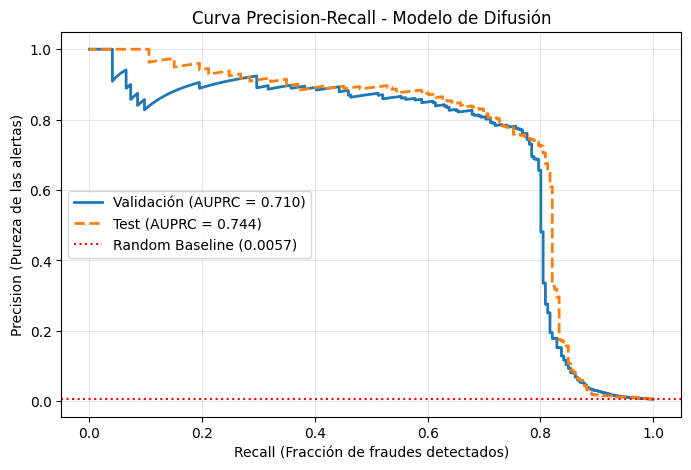

In [6]:
# ======================================================
# Task 4: Evaluation (No Threshold Yet)
# ======================================================

def evaluate_scores(y_true, scores, dataset_name="Dataset"):
    auroc = roc_auc_score(y_true, scores)
    auprc = average_precision_score(y_true, scores)
    random_baseline = y_true.mean() # Un modelo aleatorio tiene un AUPRC igual a la proporción de fraudes
    print(f"--- {dataset_name} ---")
    print(f"AUROC : {auroc:.4f} (Baseline aleatorio: 0.5000)")
    print(f"AUPRC : {auprc:.4f} (Baseline aleatorio: {random_baseline:.4f})\n")
    return auroc, auprc

val_auroc, val_auprc = evaluate_scores(y_val, val_scores_diff, "Validación (Diffusion)")
test_auroc, test_auprc = evaluate_scores(y_test, test_scores_diff, "Test (Diffusion)")

# Curvas Precision-Recall
prec_val, rec_val, _ = precision_recall_curve(y_val, val_scores_diff)
prec_test, rec_test, _ = precision_recall_curve(y_test, test_scores_diff)

plt.figure(figsize=(8, 5))
plt.plot(rec_val, prec_val, label=f'Validación (AUPRC = {val_auprc:.3f})', lw=2)
plt.plot(rec_test, prec_test, label=f'Test (AUPRC = {test_auprc:.3f})', lw=2, linestyle='--')
plt.axhline(y=y_test.mean(), color='r', linestyle=':', label=f'Random Baseline ({y_test.mean():.4f})')
plt.xlabel('Recall (Fracción de fraudes detectados)')
plt.ylabel('Precision (Pureza de las alertas)')
plt.title('Curva Precision-Recall - Modelo de Difusión')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Objetivo 5**: Selección del Umbral (Threshold Selection) en Validación
Hasta ahora el modelo nos da un número continuo (ej: 1.45, 12.8). Necesitamos elegir un número de corte (umbral) usando solamente el conjunto de Validación para decidir a partir de qué valor bloqueamos la tarjeta

Umbral Estrategia 1 (Max F1 = 0.770): 0.9137
Umbral Estrategia 2 (Recall >= 80%): 0.8281


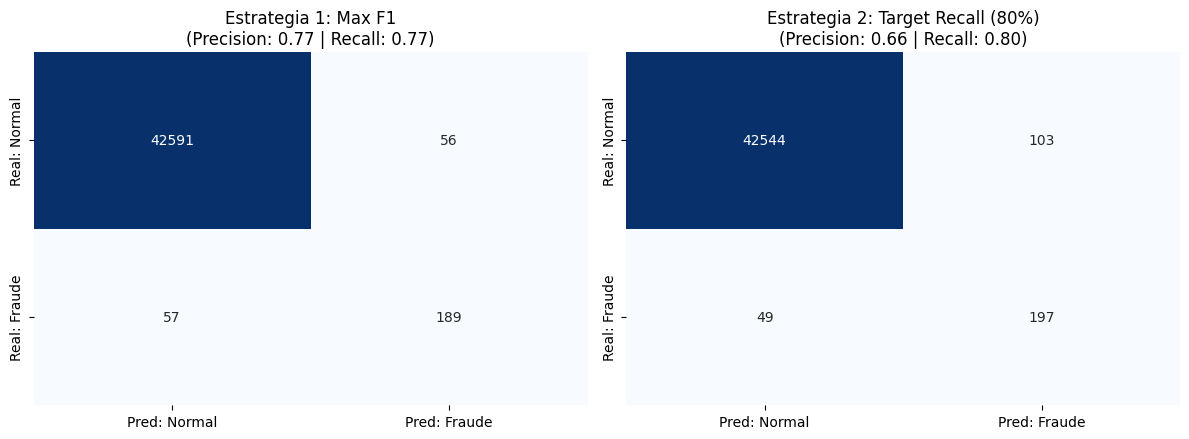

In [7]:
# ======================================================
# Task 5: Threshold Selection (Validation Set ONLY)
# ======================================================

precisions, recalls, thresholds = precision_recall_curve(y_val, val_scores_diff)
# Quitamos el último elemento de precision y recall (que siempre es 1 y 0 artificialmente en sklearn)
precisions, recalls = precisions[:-1], recalls[:-1]

# Estrategia 1: Maximizar F1-Score (Balance ideal entre Precision y Recall)
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
best_f1_idx = np.argmax(f1_scores)
thresh_max_f1 = thresholds[best_f1_idx]

# Estrategia 2: Target Recall >= 80% (Queremos atrapar al menos el 80% de los fraudes aunque haya más falsas alarmas)
target_recall = 0.80
valid_recall_indices = np.where(recalls >= target_recall)[0]
thresh_target_rec = thresholds[valid_recall_indices[-1]] # El umbral más alto que cumple >= 80% de recall

print(f"Umbral Estrategia 1 (Max F1 = {f1_scores[best_f1_idx]:.3f}): {thresh_max_f1:.4f}")
print(f"Umbral Estrategia 2 (Recall >= 80%): {thresh_target_rec:.4f}")

# Visualizar Matrices de Confusión en Validación para ambos umbrales
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, thresh, title in zip(axes, [thresh_max_f1, thresh_target_rec], ["Estrategia 1: Max F1", "Estrategia 2: Target Recall (80%)"]):
    preds = (val_scores_diff >= thresh).astype(int)
    cm = confusion_matrix(y_val, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Pred: Normal', 'Pred: Fraude'],
                yticklabels=['Real: Normal', 'Real: Fraude'])
    p = cm[1,1] / (cm[0,1] + cm[1,1] + 1e-8)
    r = cm[1,1] / (cm[1,0] + cm[1,1] + 1e-8)
    ax.set_title(f"{title}\n(Precision: {p:.2f} | Recall: {r:.2f})")

plt.tight_layout()
plt.show()

**Objetivo 6**: Evaluación Final en Test
Fijamos el umbral ganador de validación (por ejemplo, thresh_max_f1) y lo aplicamos una única vez sobre los datos de Test.

=== Resultados Finales en Test (Umbral Max-F1 fijado en Validación) ===
Precision : 0.7571
Recall    : 0.7602
FPR       : 0.0014 (Tasa de Falsos Positivos)
F1-Score  : 0.7586


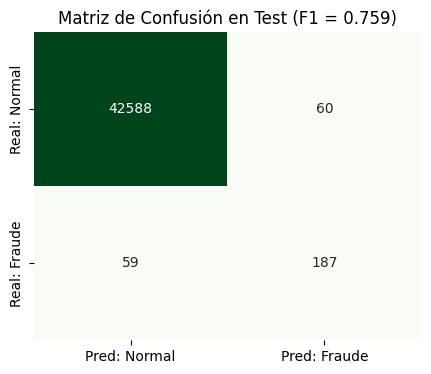

In [8]:
# ======================================================
# Task 6: Final Test Evaluation
# ======================================================

# Usamos el umbral elegido en Validación (Max F1) sin tocarlo
chosen_threshold = thresh_max_f1
test_preds = (test_scores_diff >= chosen_threshold).astype(int)

cm_test = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm_test.ravel()

precision_test = tp / (tp + fp + 1e-8)
recall_test = tp / (tp + fn + 1e-8)
fpr_test = fp / (fp + tn + 1e-8)
f1_test = f1_score(y_test, test_preds)

print("=== Resultados Finales en Test (Umbral Max-F1 fijado en Validación) ===")
print(f"Precision : {precision_test:.4f}")
print(f"Recall    : {recall_test:.4f}")
print(f"FPR       : {fpr_test:.4f} (Tasa de Falsos Positivos)")
print(f"F1-Score  : {f1_test:.4f}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Pred: Normal', 'Pred: Fraude'],
            yticklabels=['Real: Normal', 'Real: Fraude'])
plt.title(f"Matriz de Confusión en Test (F1 = {f1_test:.3f})")
plt.show()

**Objetivo 7**: Comparación con Baselines (Isolation Forest y Autoencoder)
Entrenamos dos modelos clásicos de detección de anomalías usando exactamente el mismo conjunto de entrenamiento (solo normales) y los comparamos en Test.

In [9]:
# ======================================================
# Task 7: Baseline Comparisons (Isolation Forest & Autoencoder)
# ======================================================

# ------------------------------------------------------
# Baseline 1: Isolation Forest (Árboles que aíslan puntos raros)
# ------------------------------------------------------
print("Entrenando Baseline 1: Isolation Forest...")
iso_forest = IsolationForest(n_estimators=100, random_state=42, n_jobs=-1)
iso_forest.fit(X_train_scaled) # Entrenado SOLO con datos normales

# decision_function da valores más negativos cuanto más anómalo es el dato,
# por eso le ponemos un signo menos adelante para que "mayor puntaje = más anómalo"
test_scores_if = -iso_forest.decision_function(X_test_scaled)


# ------------------------------------------------------
# Baseline 2: Autoencoder (Red neuronal que comprime y descomprime)
# ------------------------------------------------------
print("Entrenando Baseline 2: Autoencoder...")
class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        # Encoder: comprime de 29 variables a solo 8
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU()
        )
        # Decoder: intenta reconstruir las 29 variables originales desde las 8 comprimidas
        self.decoder = nn.Sequential(
            nn.Linear(8, 16),
            nn.ReLU(),
            nn.Linear(16, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

ae_model = Autoencoder(input_dim=input_dim).to(device)
ae_optimizer = torch.optim.Adam(ae_model.parameters(), lr=1e-3)

ae_model.train()
for epoch in range(15):
    for (x_batch,) in train_loader:
        x_batch = x_batch.to(device)
        recon = ae_model(x_batch)
        loss = F.mse_loss(recon, x_batch)
        ae_optimizer.zero_grad()
        loss.backward()
        ae_optimizer.step()

# Calculamos el error de reconstrucción del Autoencoder en Test
ae_model.eval()
with torch.no_grad():
    x_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32, device=device)
    recon_test = ae_model(x_test_tensor)
    test_scores_ae = torch.mean((x_test_tensor - recon_test) ** 2, dim=1).cpu().numpy()

print("¡Baselines listos!")

Entrenando Baseline 1: Isolation Forest...
Entrenando Baseline 2: Autoencoder...
¡Baselines listos!


**Objetivo 8**: Análisis Comparativo y Tabla Resumen
Aquí juntamos los tres modelos en una tabla limpia y graficamos sus curvas Precision-Recall juntas

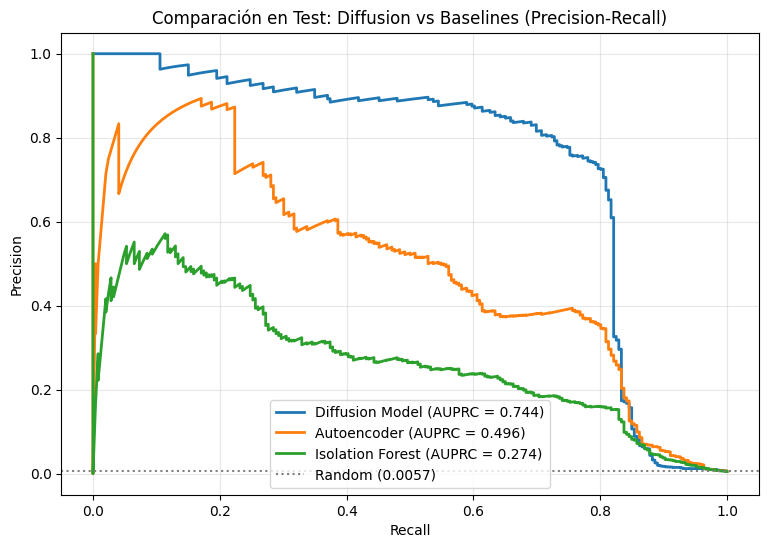

,Modelo,AUROC (Test),AUPRC (Test)
0,Diffusion Model,0.944564,0.744443
1,Autoencoder,0.959797,0.495921
2,Isolation Forest,0.948899,0.273774


In [10]:
# ======================================================
# Task 8: Comparative Analysis
# ======================================================

models_scores = {
    "Diffusion Model": test_scores_diff,
    "Autoencoder": test_scores_ae,
    "Isolation Forest": test_scores_if
}

results = []
plt.figure(figsize=(9, 6))

for name, scores in models_scores.items():
    auroc = roc_auc_score(y_test, scores)
    auprc = average_precision_score(y_test, scores)
    results.append({"Modelo": name, "AUROC (Test)": auroc, "AUPRC (Test)": auprc})

    prec, rec, _ = precision_recall_curve(y_test, scores)
    plt.plot(rec, prec, lw=2, label=f"{name} (AUPRC = {auprc:.3f})")

plt.axhline(y=y_test.mean(), color='gray', linestyle=':', label=f"Random ({y_test.mean():.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Comparación en Test: Diffusion vs Baselines (Precision-Recall)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

results_df = pd.DataFrame(results).sort_values(by="AUPRC (Test)", ascending=False)
display(results_df)

# 1. **¿Qué método funciona mejor aquí?**
El Modelo de Difusión es el claro ganador en este escenario. Aunque los tres modelos muestran un rendimiento engañosamente similar en AUROC (~0.945 – 0.960), al evaluar el AUPRC —que es la métrica crítica bajo desbalance extremo— el Modelo de Difusión alcanza 0.7444, superando por un amplio margen al Autoencoder (0.4959) y casi triplicando al Isolation Forest (0.2738). Esto significa que el modelo de difusión genera muchas menos falsas alarmas para un mismo nivel de detección de fraudes.
#2. **¿Por qué ocurre esto?**
Frente a Isolation Forest (0.2738 AUPRC): Isolation Forest aísla puntos haciendo cortes aleatorios eje por eje. En espacios de 29 dimensiones donde las anomalías dependen de combinaciones sutiles entre variables, los cortes ortogonales generan demasiados falsos positivos.   Frente al Autoencoder (0.4959 AUPRC): Curiosamente, el Autoencoder tiene el AUROC más alto (0.9598) pero cae fuerte en AUPRC. Esto sucede porque los Autoencoders sufren de sobre-generalización: su cuello de botella fijo logra reconstruir medianamente bien algunas anomalías moderadas, o bien asigna errores altos a transacciones normales atípicas (compras grandes pero legítimas), desplomando la precisión en el top de alertas.   Por qué gana Difusión (0.7444 AUPRC): Al entrenar la red para eliminar ruido en múltiples escalas de tiempo ($t$), el modelo aprende la estructura exacta de la distribución de datos normales (el gradiente de la densidad de probabilidad). Al promediar el error de predicción de ruido en varios pasos $t$, separa de forma mucho más limpia los fraudes verdaderos de las transacciones normales inusuales.

#3. **¿Qué ofrece la difusión más allá del rendimiento puro?**
Detección multi-escala sin cuello de botella: No requiere fijar arbitrariamente una dimensión de compresión latente como el Autoencoder, y evalúa tanto anomalías finas/locales ($t$ pequeños) como globales ($t$ grandes).Explicabilidad y contrafactuales: Al ser un modelo generativo iterativo, permite tomar una transacción fraudulenta y aplicarle el proceso inverso de limpieza (denoising) para ver hacia qué transacción "normal" converge, explicándole a un analista qué variables específicas hicieron saltar la alarma.Generación de datos sintéticos: Puede utilizarse para muestrear nuevas transacciones normales sintéticas (por ejemplo, para compartir datos bancarios cuidando la privacidad).